In [17]:
import pandas as pd
import numpy as np

df = pd.read_csv('student_grade_ses_dataset.csv')
df.head()

,student_id,academic_year,survey_date,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,...,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class,at_risk_flag
0,STU101529,2024-2025,6/3/25,16,Male,12,Government,Rural,3,0,...,4.0,No Scholarship,0,4,15.0,76.8,61.7,59.4,D,0
1,STU107546,2022-2023,2/5/25,15,Male,10,Government,Urban,3,1,...,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C,0
2,STU103737,2024-2025,21/3/25,14,Male,9,Government,Urban,2,0,...,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D,0
3,STU108172,2023-2024,30/3/25,13,Male,8,Government,Rural,6,4,...,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D,0
4,STU110633,2023-2024,6/5/25,11,Female,6,Private-Unaided,Rural,5,3,...,9.1,No Scholarship,0,5,13.9,86.0,79.3,88.7,B,0


In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12025 entries, 0 to 12024
Data columns (total 29 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  12025 non-null  str    
 1   academic_year               12025 non-null  str    
 2   survey_date                 12025 non-null  str    
 3   age                         12025 non-null  int64  
 4   gender                      12025 non-null  str    
 5   grade_level                 12025 non-null  int64  
 6   school_type                 12025 non-null  str    
 7   residence_type              12025 non-null  str    
 8   family_size                 12025 non-null  int64  
 9   num_siblings                12025 non-null  int64  
 10  single_parent_household     12025 non-null  int64  
 11  family_income_bracket       12025 non-null  str    
 12  annual_family_income_inr    11304 non-null  float64
 13  father_education_level      11605 non-null

## Drop unneeded columns

In [19]:
# Confirm duplicated student_ids are duplicate rows

# 1. Rows that share the same 'id'
id_dups = df[df.duplicated(subset=['student_id'], keep=False)]

# 2. Rows that share the same 'id' AND are identical across ALL columns
full_dups = df[df.duplicated(subset=['student_id'], keep=False) & df.duplicated(keep=False)]

print(f"Total rows with duplicate IDs: {len(id_dups)}")
print(f"Rows with duplicate IDs that are FULLY identical: {len(full_dups)}")
print(f"Rows with duplicate IDs that have DIFFERENCES: {len(id_dups) - len(full_dups)}")

df = df.drop_duplicates(subset=['student_id']) 

Total rows with duplicate IDs: 50
Rows with duplicate IDs that are FULLY identical: 50
Rows with duplicate IDs that have DIFFERENCES: 0


In [20]:
df = df.drop(columns=['student_id', 'survey_date', 'at_risk_flag'])

df.shape


(12000, 26)

In [21]:
parents = np.where(df['single_parent_household'] == 1, 1, 2)

# Filter rows where family_size does not match expected size
mismatches = df[df['family_size'] < (parents + df['num_siblings'] + 1)]

mismatches

,academic_year,age,gender,grade_level,school_type,residence_type,family_size,num_siblings,single_parent_household,family_income_bracket,...,has_computer_or_laptop,distance_to_school_km,scholarship_status,extra_tutoring,parental_involvement_score,study_hours_per_week,attendance_rate_pct,previous_year_grade_pct,final_grade_pct,grade_class
1,2022-2023,15,Male,10,Government,Urban,3,1,0,Middle,...,1,0.7,No Scholarship,0,3,20.9,74.5,49.2,60.2,C
2,2024-2025,14,Male,9,Government,Urban,2,0,0,Low,...,0,2.9,No Scholarship,0,4,20.9,94.9,56.9,58.4,D
3,2023-2024,13,Male,8,Government,Rural,6,4,0,Lower-Middle,...,0,7.0,No Scholarship,0,1,6.5,63.6,49.3,57.0,D
19,2022-2023,13,Female,8,Private-Unaided,Rural,3,1,0,Middle,...,0,2.2,Partial,1,4,17.9,74.0,71.4,75.0,B
22,2022-2023,13,Male,7,Private-Unaided,Urban,6,4,0,Lower-Middle,...,1,2.2,Partial,0,4,22.5,100.0,43.3,55.5,D
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12014,2024-2025,13,Female,7,Government,Urban,5,3,0,Middle,...,1,7.7,Partial,0,3,13.1,84.2,61.2,78.2,B
12018,2021-2022,13,Female,9,Government,Urban,3,1,0,Lower-Middle,...,0,1.0,No Scholarship,0,3,19.0,89.4,69.2,68.6,C
12019,2021-2022,10,Female,6,Government-Aided,Semi-Urban,5,3,0,Lower-Middle,...,0,0.7,Partial,0,3,18.3,91.2,68.1,79.0,B
12022,2024-2025,15,Male,9,Government-Aided,Rural,6,4,0,Low,...,0,4.1,Partial,0,2,10.1,80.7,48.5,49.9,D


In real-world educational surveys (like OECD PISA or Census data), student answers reflect messy real-world dynamics (e.g., step-siblings living in a separate home part-time, or shared custody arrangements). Leaving these values intact lets non-parametric models ($k$-NN, GAMs, Decision Trees) handle messy, real-world edge cases natively.

## Handling NULL values

In [22]:
# Null in rows
null_row_counts = df.isnull().any(axis=1).sum()
print("null_row_counts:", null_row_counts)

# Null in columns
null_counts = df.isnull().sum()
print("null_col_counts:")
print(null_counts[null_counts > 0])


null_row_counts: 3215
null_col_counts:
annual_family_income_inr    720
father_education_level      420
mother_education_level      360
father_occupation           480
mother_occupation           600
has_internet_access         180
distance_to_school_km       240
attendance_rate_pct         300
previous_year_grade_pct     360
dtype: int64


In [23]:
grade_null_breakdown = (
    df[df['previous_year_grade_pct'].isna()]
    .value_counts(subset=['grade_level'])
    .sort_index()
    .rename_axis('Grade Level')
    .reset_index(name='Missing Grade Count')
)

display(grade_null_breakdown)

,Grade Level,Missing Grade Count
0,6,49
1,7,58
2,8,56
3,9,46
4,10,43
5,11,56
6,12,52


In [24]:
cols_to_check = [
    'father_education_level', 
    'mother_education_level', 
    'father_occupation', 
    'mother_occupation'
]

# Detailed counts of missing values grouped by single_parent_household
null_counts_by_single_parent = df.groupby('single_parent_household')[cols_to_check].apply(
    lambda group: group.isnull().sum()
)

# Add total row counts per group for context
null_counts_by_single_parent['total_households'] = df.groupby('single_parent_household').size()
print(null_counts_by_single_parent)

                         father_education_level  mother_education_level  \
single_parent_household                                                   
0                                           371                     303   
1                                            49                      57   

                         father_occupation  mother_occupation  \
single_parent_household                                         
0                                      403                521   
1                                       77                 79   

                         total_households  
single_parent_household                    
0                                   10318  
1                                    1682  


### 1. Missing parents occupation / education
- I thought it was related to single_parent_household, but it had the reverse effect.
- Of the NULL parent occupation / educations, most of them were from double_parent_household.
- Recommendation: use "Undisclosed" for missing occupation and education values when the information is unknown. Use "Not Applicable" only when the parent or role is structurally absent and the data confirms that; single_parent_household alone is not enough to assume this.

#### 2. Missing previous year grade pct
- Intially thought it might've been due to students being in the lowest grade and having no prior pct.
- But data shows otherwise.
- Recommendation: impute using the training-fold median for the student's grade level.

#### 3. Missing parental income
- Infer from occupation.
- Need to show a relation between both parents' occupations and income.

#### 4. Missing distance_to_school_km
- Compare observed distance by residence_type and school_type in the table below.
- Distance varies strongly by residence type, while school-type differences within residence groups are small.
- Recommendation: impute with the training-fold median for residence_type; use the training-fold overall median if the residence group has no observed distances.

#### 5. Missing has_internet_access
- Perhaps impute based on relation to computer or age?
- Likely refers to student's access to the internet.

#### 6. Missing attendance_rate_pct

### Residence-specific distance summaries and candidate imputation values

The mean and median below describe observed distances in each residence group. The median is the candidate fill value; the mean is included for comparison. Counts and the interquartile range show how much observed data support each summary.

In [25]:
_distance_col = 'distance_to_school_km'
_distance_by_residence = (
    df.groupby('residence_type')[_distance_col]
      .agg(
          total_students='size',
          observed_distances='count',
          missing_distances=lambda s: s.isna().sum(),
          mean_distance='mean',
          median_distance='median',
          q1=lambda s: s.quantile(0.25),
          q3=lambda s: s.quantile(0.75),
      )
      .round(2)
      .sort_values('mean_distance')
)
display(_distance_by_residence)

# Fallback if a residence group has no observed distances in a training fold.
_distance_overall_fallback = df[_distance_col].median()
print(f'Overall-median fallback: {_distance_overall_fallback:.2f} km')

,total_students,observed_distances,missing_distances,mean_distance,median_distance,q1,q3
residence_type,,,,,,,
Urban,5026,4935,91,1.98,1.7,1.0,2.7
Semi-Urban,2750,2695,55,3.54,3.0,1.7,4.8
Rural,4224,4130,94,6.37,5.4,3.1,8.6


Overall-median fallback: 2.80 km


### Parental education and occupation versus family income

These predictors are categorical, so a Pearson correlation is not appropriate. Compare group counts, income medians and means, and the share of variation in log income associated with each category (eta-squared). Income is skewed, so the log-income association is useful alongside the raw-income summaries. These are descriptive associations, not causal effects.

In [26]:
_income_col = 'annual_family_income_inr'
_parent_income_features = [
    'father_education_level', 'mother_education_level',
    'father_occupation', 'mother_occupation',
]
_income_summary_tables = {}
_income_association = []

for feature in _parent_income_features:
    _valid = df[[feature, _income_col]].dropna().copy()
    _valid = _valid[_valid[_income_col] > 0]
    _valid['log_income_for_assoc'] = np.log(_valid[_income_col])

    _group_summary = (
        _valid.groupby(feature)[_income_col]
        .agg(
            students='count',
            mean_income='mean',
            median_income='median',
            q1=lambda s: s.quantile(0.25),
            q3=lambda s: s.quantile(0.75),
        )
        .round(0)
        .reset_index()
        .rename(columns={feature: 'category'})
    )
    if feature in ['father_education_level', 'mother_education_level']:
        education_order = [
            'No Formal Education', 'Primary', 'Secondary', 'Higher Secondary',
            "Bachelor's Degree", "Master's Degree", 'Doctorate',
        ]
        _group_summary['_category_order'] = pd.Categorical(
            _group_summary['category'], categories=education_order, ordered=True
        )
        _group_summary = _group_summary.sort_values('_category_order').drop(
            columns='_category_order'
        )
    else:
        _group_summary = _group_summary.sort_values('median_income')
    _income_summary_tables[feature] = _group_summary

    _grand_mean = _valid['log_income_for_assoc'].mean()
    _ss_total = ((_valid['log_income_for_assoc'] - _grand_mean) ** 2).sum()
    _ss_between = sum(
        len(group) * (group['log_income_for_assoc'].mean() - _grand_mean) ** 2
        for _, group in _valid.groupby(feature)
    )
    _income_association.append({
        'parent_feature': feature,
        'students_with_income_and_category': len(_valid),
        'eta_squared_log_income': _ss_between / _ss_total,
    })

for feature in _parent_income_features:
    print(feature.replace('_', ' ').title())
    display(_income_summary_tables[feature])

_income_association_summary = pd.DataFrame(_income_association).sort_values(
    'eta_squared_log_income', ascending=False
)
display(_income_association_summary.round(3))

Father Education Level


,category,students,mean_income,median_income,q1,q3
4,No Formal Education,758,225880.0,169100.0,102009.0,283200.0
5,Primary,1901,308834.0,215922.0,115819.0,356835.0
6,Secondary,2674,416422.0,295321.0,182226.0,510588.0
2,Higher Secondary,1970,548910.0,363974.0,208215.0,607278.0
0,Bachelor's Degree,2235,893943.0,535518.0,302254.0,1009545.0
3,Master's Degree,1003,1374011.0,847486.0,442968.0,1662763.0
1,Doctorate,344,1840297.0,1234026.0,631070.0,2814080.0


Mother Education Level


,category,students,mean_income,median_income,q1,q3
4,No Formal Education,782,212878.0,167272.0,102510.0,269292.0
5,Primary,1849,320523.0,221994.0,120122.0,368509.0
6,Secondary,2632,402809.0,288928.0,177799.0,492068.0
2,Higher Secondary,2043,572064.0,366327.0,208292.0,611550.0
0,Bachelor's Degree,2279,874271.0,539682.0,320500.0,996111.0
3,Master's Degree,1005,1395397.0,880943.0,449372.0,1820274.0
1,Doctorate,353,1885989.0,1248661.0,624488.0,2914109.0


Father Occupation


,category,students,mean_income,median_income,q1,q3
5,Unemployed,1895,488087.0,282871.0,155939.0,524788.0
6,Unskilled Labor,1276,518549.0,295644.0,162189.0,553442.0
4,Skilled Labor / Trade,1749,615948.0,349104.0,195733.0,635585.0
0,Business / Self-Employed,1435,661843.0,356744.0,196812.0,676614.0
1,Clerical / Service,1598,650028.0,364001.0,193798.0,672029.0
3,Professional,1588,776331.0,426407.0,224858.0,847751.0
2,Managerial / Executive,1281,820541.0,447828.0,223040.0,841918.0


Mother Occupation


,category,students,mean_income,median_income,q1,q3
6,Unemployed,1518,451902.0,263815.0,137084.0,484722.0
7,Unskilled Labor,1078,455198.0,272869.0,140087.0,509133.0
5,Skilled Labor / Trade,1433,611771.0,318197.0,171979.0,605494.0
0,Business / Self-Employed,1232,652902.0,329176.0,176182.0,663652.0
1,Clerical / Service,1237,660644.0,338151.0,176760.0,653748.0
3,Managerial / Executive,1025,707031.0,385756.0,195912.0,733422.0
4,Professional,1355,771470.0,411969.0,214434.0,825610.0
2,Homemaker,1838,799111.0,459398.0,294298.0,865110.0


,parent_feature,students_with_income_and_category,eta_squared_log_income
1,mother_education_level,10943,0.260
0,father_education_level,10885,0.254
3,mother_occupation,10716,0.050
2,father_occupation,10822,0.024


## Target and predictors

In [27]:
TARGET_COL = 'final_grade_pct'

# Heavily skewed income, so log-transformed

df['log_income'] = np.log(df['annual_family_income_inr'])

CONTINUOUS_COLS = ['distance_to_school_km', 'study_hours_per_week', 'attendance_rate_pct',

                   'previous_year_grade_pct', 'log_income']

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score

DISCRETE_COLS = ['age', 'grade_level', 'family_size', 'num_siblings', 'single_parent_household',

                 'has_internet_access', 'has_computer_or_laptop', 'extra_tutoring',

                 'parental_involvement_score']

# Match Project.ipynb predictor set.

CATEGORICAL_COLS = ['academic_year', 'gender', 'school_type', 'residence_type', 'family_income_bracket',

                    'father_education_level', 'mother_education_level', 'father_occupation',

                    'mother_occupation', 'scholarship_status']

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS

PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS


In [28]:
X = df[PREDICTOR_COLS]

Y = df[TARGET_COL]

print('X:', X.shape, ' Y:', Y.shape)

# Match Project.ipynb: stratified 85/15 split; use training data for CV only.

from sklearn.model_selection import train_test_split

TEST_SIZE = 0.15

SEED = 42

X_train, X_test, Y_train, Y_test = train_test_split(

    X, Y, test_size=TEST_SIZE, stratify=df['grade_class'], random_state=SEED)

print('train:', X_train.shape, ' test:', X_test.shape)


X: (12000, 24)  Y: (12000,)
train: (10200, 24)  test: (1800, 24)


## GAM

### K-fold cross-validation for GAM lambda selection

Match Project.ipynb: stratified 85/15 split with `random_state=42`; use shuffled 10-fold CV on training rows to select lambda. The test rows remain separate and are scored once after refitting. Each fold computes imputation and factor encoding using its training rows only.


In [29]:
from pygam import LinearGAM, s, f
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error
import matplotlib.pyplot as plt

_gam_feature_cols = CONTINUOUS_COLS + DISCRETE_COLS + CATEGORICAL_COLS


def make_gam_terms():
    terms = None
    for col in CONTINUOUS_COLS:
        idx = _gam_feature_cols.index(col)
        term = s(idx, n_splines=10)
        terms = term if terms is None else terms + term

    for col in DISCRETE_COLS + CATEGORICAL_COLS:
        idx = _gam_feature_cols.index(col)
        term = f(idx)
        terms = terms + term
    return terms


def prepare_gam_fold(
    train_idx, valid_idx, X_source=None, y_source=None,
    X_valid_source=None, y_valid_source=None
):
    X_source = X_train if X_source is None else X_source
    y_source = Y_train if y_source is None else y_source
    X_valid_source = X_source if X_valid_source is None else X_valid_source
    y_valid_source = y_source if y_valid_source is None else y_valid_source

    X_fold_train = X_source.iloc[train_idx][_gam_feature_cols].copy()
    X_fold_valid = X_valid_source.iloc[valid_idx][_gam_feature_cols].copy()
    y_fold_train = y_source.iloc[train_idx].astype(float)
    y_fold_valid = y_valid_source.iloc[valid_idx].astype(float)

    # Impute distance by residence type, with an overall median fallback.
    distance_col = 'distance_to_school_km'
    distance_by_residence = X_fold_train.groupby('residence_type')[distance_col].median()
    overall_distance_median = X_fold_train[distance_col].median()
    for X_part in (X_fold_train, X_fold_valid):
        missing_distance = X_part[distance_col].isna()
        X_part.loc[missing_distance, distance_col] = (
            X_part.loc[missing_distance, 'residence_type'].map(distance_by_residence)
        )
        X_part[distance_col] = X_part[distance_col].fillna(overall_distance_median)

    # Impute other continuous columns using training-fold medians.
    other_continuous = [col for col in CONTINUOUS_COLS if col != distance_col]
    continuous_medians = X_fold_train[other_continuous].median()
    X_fold_train[other_continuous] = X_fold_train[other_continuous].fillna(continuous_medians)
    X_fold_valid[other_continuous] = X_fold_valid[other_continuous].fillna(continuous_medians)

    # Impute factors by their training-fold mode and encode using shared levels.
    category_levels = {}
    for col in DISCRETE_COLS + CATEGORICAL_COLS:
        mode = X_fold_train[col].mode(dropna=True).iloc[0]
        X_fold_train[col] = X_fold_train[col].fillna(mode)
        X_fold_valid[col] = X_fold_valid[col].fillna(mode)
        levels = list(pd.unique(X_fold_train[col]))
        category_levels[col] = levels
        X_fold_valid[col] = X_fold_valid[col].where(X_fold_valid[col].isin(levels), mode)
        X_fold_train[col] = pd.Categorical(X_fold_train[col], categories=levels).codes
        X_fold_valid[col] = pd.Categorical(X_fold_valid[col], categories=levels).codes

    return (
        X_fold_train.astype(float).to_numpy(),
        X_fold_valid.astype(float).to_numpy(),
        y_fold_train,
        y_fold_valid,
        category_levels,
    )

,lambda,mean_RMSE,sd_RMSE
0,0.001,9.673050,0.289927
1,0.010,9.665804,0.292906
2,0.100,9.659076,0.294967
3,1.000,9.652079,0.293767
4,10.000,9.642864,0.292992
5,100.000,9.633557,0.295026
6,1000.000,9.649767,0.294675
7,10000.000,9.743665,0.290371
8,100000.000,9.797292,0.289325


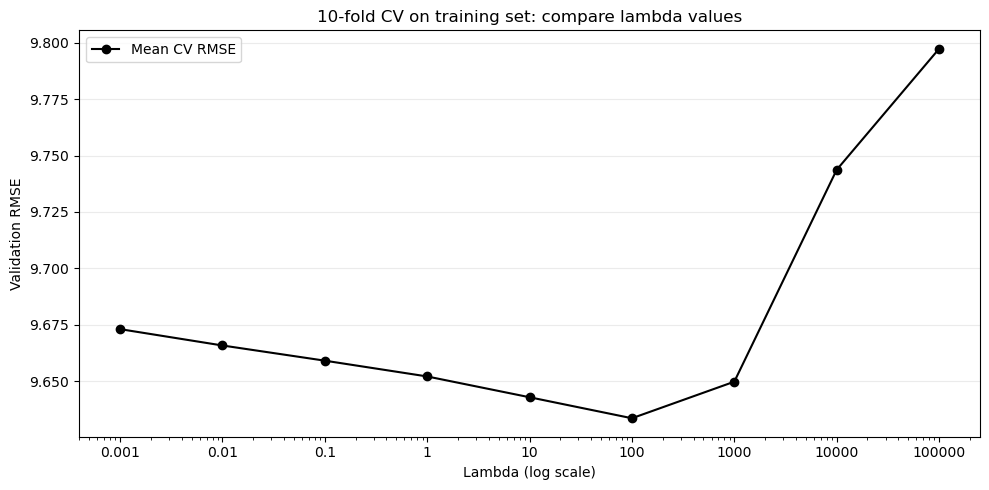

Selected lambda: 100


In [30]:
# Match Project.ipynb Lasso CV: 10 shuffled folds on training rows only.

lam_values = np.array([0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000])

kfold = KFold(n_splits=10, shuffle=True, random_state=SEED)

cv_rmse = {lam: [] for lam in lam_values}

for fold_train_idx, fold_valid_idx in kfold.split(X_train):

    X_fold_train, X_fold_valid, y_fold_train, y_fold_valid, _ = prepare_gam_fold(

        fold_train_idx, fold_valid_idx

    )

    for lam in lam_values:

        fold_gam = LinearGAM(make_gam_terms(), lam=lam)

        fold_gam.fit(X_fold_train, y_fold_train.to_numpy())

        fold_pred = fold_gam.predict(X_fold_valid)

        cv_rmse[lam].append(mean_squared_error(y_fold_valid, fold_pred) ** 0.5)

cv_summary = pd.DataFrame({

    'lambda': list(cv_rmse.keys()),

    'mean_RMSE': [np.mean(scores) for scores in cv_rmse.values()],

    'sd_RMSE': [np.std(scores, ddof=1) for scores in cv_rmse.values()],

}).sort_values('lambda')

display(cv_summary)

plt.figure(figsize=(10, 5))

plt.plot(lam_values, [np.mean(cv_rmse[lam]) for lam in lam_values],

         marker='o', color='black', label='Mean CV RMSE')

plt.xscale('log')

plt.xticks(lam_values, [f'{lam:g}' for lam in lam_values])

plt.xlabel('Lambda (log scale)')

plt.ylabel('Validation RMSE')

plt.title('10-fold CV on training set: compare lambda values')

plt.legend()

plt.grid(axis='y', alpha=0.25)

plt.tight_layout()

plt.show()

best_lam = cv_summary.loc[cv_summary['mean_RMSE'].idxmin(), 'lambda']

print(f'Selected lambda: {best_lam:g}')


In [31]:
# Refit on all training rows, then evaluate once on the held-out test set.

_train_indices = np.arange(len(X_train))

_test_indices = np.arange(len(X_test))

X_gam_train, _, y_gam_train, _, _gam_category_levels = prepare_gam_fold(

    _train_indices, _train_indices

)

# Prepare test predictors using preprocessing statistics and factor levels learned on training rows.

_, X_gam_test, _, y_gam_test, _ = prepare_gam_fold(
    _train_indices, _test_indices,
    X_source=X_train, y_source=Y_train, X_valid_source=X_test, y_valid_source=Y_test
)

gam = LinearGAM(make_gam_terms(), lam=best_lam).fit(

    X_gam_train, y_gam_train.to_numpy()

)

test_pred = gam.predict(X_gam_test)

test_rmse = mean_squared_error(y_gam_test, test_pred) ** 0.5

print(gam.summary())

print(f'Held-out test RMSE: {test_rmse:.3f}')


LinearGAM                                                                                                 
=============================================== ==========================================================
Distribution:                        NormalDist Effective DoF:                                     81.6897
Link Function:                     IdentityLink Log Likelihood:                                -37497.6683
Number of Samples:                        10200 AIC:                                             75160.716
                                                AICc:                                           75162.0841
                                                GCV:                                               93.4219
                                                Scale:                                              9.5956
                                                Pseudo R-Squared:                                   0.3321
Feature Function                  Lam

C:\Users\Admin\AppData\Local\Temp\ipykernel_27116\29790975.py:30: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  print(gam.summary())


## KNN

### K-fold cross-validation for KNN regression

Tune the neighbor count `k` using 10-fold CV on the training set, matching the split and CV setup in Project.ipynb. The held-out test set is scored once after GridSearchCV refits the best pipeline on training rows.


Held-out test RMSE: 10.215


,k,mean_RMSE,sd_RMSE
0,1,14.114616,0.214512
1,3,11.478831,0.260779
2,5,10.886505,0.265718
3,7,10.663030,0.241505
4,11,10.395469,0.211614
5,15,10.271079,0.195793
6,21,10.202129,0.197273
7,31,10.162160,0.192431
8,41,10.135224,0.199720
9,51,10.120716,0.197908


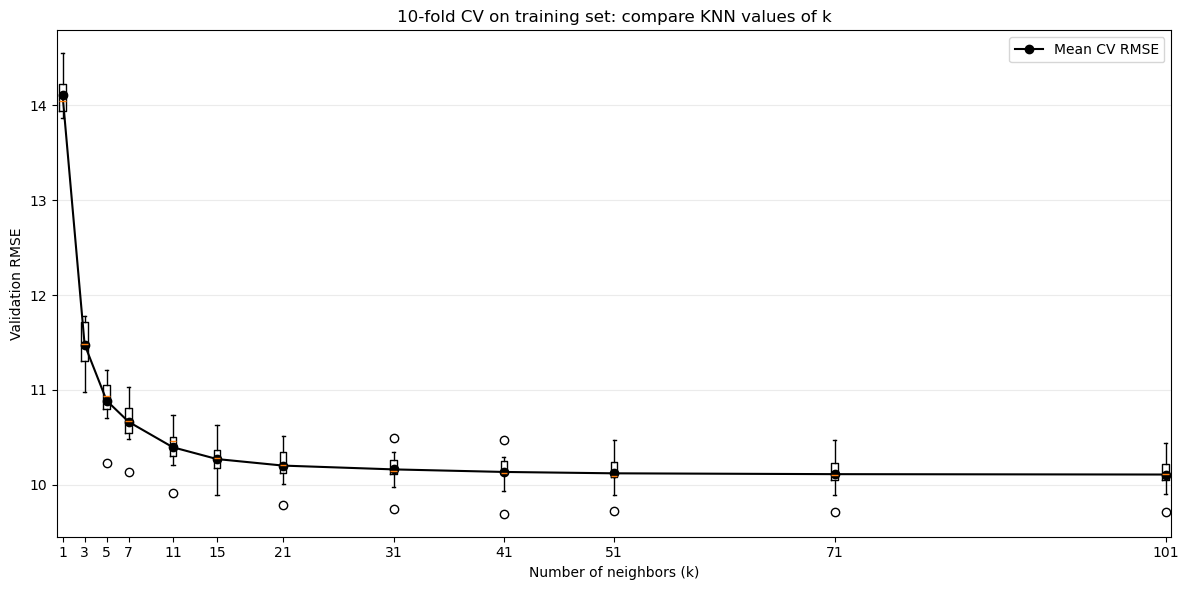

Best k: 101
Best mean CV RMSE: 10.108


In [32]:
from sklearn.compose import ColumnTransformer

from sklearn.impute import SimpleImputer

from sklearn.model_selection import GridSearchCV, KFold

from sklearn.neighbors import KNeighborsRegressor

from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Separate KNN inputs: the CV pipeline handles all preprocessing fold by fold.

_knn_X = X_train.copy()

_knn_y = Y_train.copy()

_knn_numeric_pipeline = Pipeline([

    ('imputer', SimpleImputer(strategy='median')),

    ('scaler', StandardScaler()),

])

_knn_categorical_pipeline = Pipeline([

    ('imputer', SimpleImputer(strategy='most_frequent')),

    ('onehot', OneHotEncoder(handle_unknown='ignore')),

])

_knn_preprocessor = ColumnTransformer([

    ('numeric', _knn_numeric_pipeline, NUMERIC_COLS),

    ('categorical', _knn_categorical_pipeline, CATEGORICAL_COLS),

])

from sklearn.base import BaseEstimator, TransformerMixin

class ResidenceDistanceImputer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):

        self.overall_median_ = X['distance_to_school_km'].median()

        self.median_by_residence_ = X.groupby('residence_type')['distance_to_school_km'].median()

        return self

    def transform(self, X):

        X = X.copy()

        missing = X['distance_to_school_km'].isna()

        by_residence = X.loc[missing, 'residence_type'].map(self.median_by_residence_)

        X.loc[missing, 'distance_to_school_km'] = by_residence.fillna(self.overall_median_)

        return X

_knn_pipeline = Pipeline([

    ('distance_imputer', ResidenceDistanceImputer()),

    ('preprocess', _knn_preprocessor),

    ('knn', KNeighborsRegressor()),

])

_k_values = [1, 3, 5, 7, 11, 15, 21, 31, 41, 51, 71, 101]

_knn_cv = KFold(n_splits=10, shuffle=True, random_state=SEED)

_knn_search = GridSearchCV(

    estimator=_knn_pipeline,

    param_grid={'knn__n_neighbors': _k_values},

    scoring='neg_root_mean_squared_error',

    cv=_knn_cv,

    n_jobs=-1,

    return_train_score=False,

    refit=True,

)

_knn_search.fit(_knn_X, _knn_y)

_knn_test_pred = _knn_search.predict(X_test)

_knn_test_rmse = mean_squared_error(Y_test, _knn_test_pred) ** 0.5

print(f'Held-out test RMSE: {_knn_test_rmse:.3f}')

# Display k values in ascending order; lower RMSE is better.

_knn_cv_summary = pd.DataFrame({

    'k': _knn_search.cv_results_['param_knn__n_neighbors'].astype(int),

    'mean_RMSE': -_knn_search.cv_results_['mean_test_score'],

    'sd_RMSE': _knn_search.cv_results_['std_test_score'],

}).sort_values('k')

display(_knn_cv_summary)

_knn_fold_rmse = {

    k: [

        -_knn_search.cv_results_[f'split{fold}_test_score'][row]

        for fold in range(_knn_cv.get_n_splits())

    ]

    for row, k in enumerate(_knn_search.cv_results_['param_knn__n_neighbors'].astype(int))

}

plt.figure(figsize=(12, 6))

plt.boxplot(

    [_knn_fold_rmse[k] for k in _k_values],

    positions=_k_values,

    widths=0.6,

)

plt.plot(

    _k_values,

    [_knn_cv_summary.loc[_knn_cv_summary['k'] == k, 'mean_RMSE'].iloc[0] for k in _k_values],

    marker='o', color='black', label='Mean CV RMSE',

)

plt.xticks(_k_values, [str(k) for k in _k_values])

plt.xlabel('Number of neighbors (k)')

plt.ylabel('Validation RMSE')

plt.title('10-fold CV on training set: compare KNN values of k')

plt.legend()

plt.grid(axis='y', alpha=0.25)

plt.tight_layout()

plt.show()

print('Best k:', _knn_search.best_params_['knn__n_neighbors'])

print(f'Best mean CV RMSE: {-_knn_search.best_score_:.3f}')

# GridSearchCV refits the best pipeline on all training rows; it is available as:

knn_model = _knn_search.best_estimator_
